In [44]:
#Import libraries
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [47]:
#Load the csv files
roads=pd.read_csv("../data/roads.csv")
traffic=pd.read_csv("../data/traffic.csv")

In [48]:
#create the graph
#manually
'''
G=nx.Graph()
for each row in roads:
    G.add_edge(
        row["source"],row["destination"],
        distance=row["distance"],
        speed_limit=row["speed_limit"],
        road_type=row["road_type"]
    )
'''
#by networkx
G=nx.from_pandas_edgelist(
    roads,
    source="source",
    target="destination",
    edge_attr=True        
)


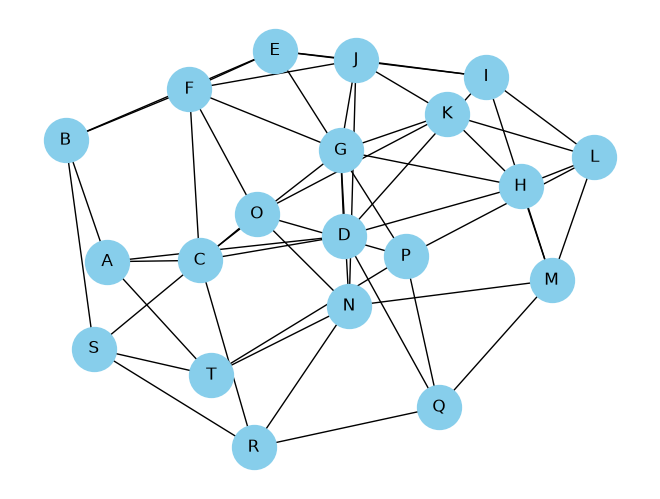

In [49]:
#visualize the graph
nx.draw(G,with_labels=True,node_color="skyblue",node_size=1000)
plt.show()

In [50]:
traffic.head()

,time,weather,road_type,distance,actual_speed
0,7,Sunny,Highway,5,62
1,7,Rain,Highway,5,38
2,7,Cloudy,Highway,6,54
3,8,Sunny,Highway,5,58
4,8,Rain,Highway,5,34


In [51]:
#data preprocessing : one that ml will understand
#x :Features
x=traffic[
    [
        "weather","road_type"
    ]
]
#y :Target
y=traffic["actual_speed"]

In [52]:
#One hot encoding 
x=pd.get_dummies(
    x,
    columns=["road_type", "weather" ]
)

In [53]:
#Train test split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [68]:
#model train
model=DecisionTreeRegressor(random_state=42)

#fit train learn
model.fit(x_train,y_train)

#predictions
predictions=model.predict(x_test)

#comparisions
comparision=pd.DataFrame({
    "Actual":y_test.values,
    "Predicted":predictions
})


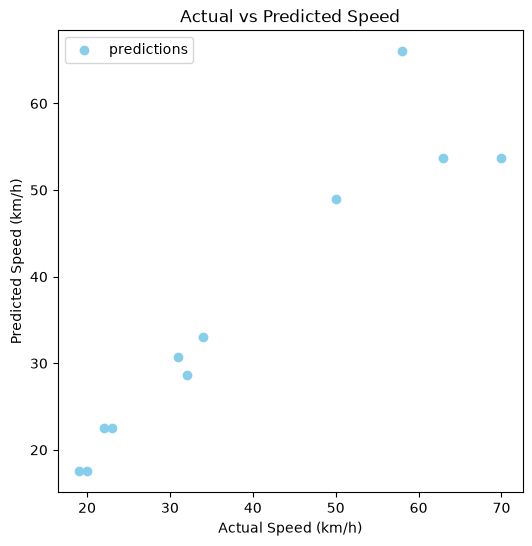

In [55]:
#visualize
plt.figure(figsize=(6,6))
plt.scatter(y_test,predictions,c="skyblue",label="predictions")

plt.xlabel("Actual Speed (km/h)")
plt.ylabel("Predicted Speed (km/h)")
plt.title("Actual vs Predicted Speed")
plt.legend()
plt.show()

In [59]:
#shortest path
path=nx.shortest_path(G,source="A",target="E",weight="distance")
print(path)
#shortest path distance
distance = nx.shortest_path_length(
    G,
    source="A",
    target="E",
    weight="distance"
)

print(distance)

['A', 'C', 'F', 'E']
8


In [61]:
#adding a colummn travel time

for u,v,data in G.edges(data=True):
    data["travel_time"]=data["distance"]/data["speed_limit"]

In [75]:
#predict speed
def predict_speed(distance, road_type, time, weather):

    row = {
        "time": time,
        "distance": distance,
        "weather": weather,
        "road_type": road_type
    }

    row = pd.DataFrame([row])

    row = pd.get_dummies(row)

    row = row.reindex(
        columns=x_train.columns,
        fill_value=0
    )

    predicted_speed = model.predict(row)[0]

    return predicted_speed

In [76]:
#previosly we were using the speed limit now we will use the predicted speed for travel time
for u, v, data in G.edges(data=True):

    predicted_speed = predict_speed(
        distance=data["distance"],
        road_type=data["road_type"],
        time=8,
        weather="Rain"
    )

    data["travel_time"] = data["distance"] / predicted_speed

In [77]:
#Dijkstra Algo
import heapq

def dijkstra(graph, start, end):

    queue = [(0, start)]
    distances = {node: float('inf') for node in graph.nodes()}
    distances[start] = 0

    previous = {}

    while queue:

        current_distance, current_node = heapq.heappop(queue)

        if current_node == end:
            break

        for neighbor in graph.neighbors(current_node):

            edge = graph[current_node][neighbor]
            weight = edge["travel_time"]

            distance = current_distance + weight

            if distance < distances[neighbor]:

                distances[neighbor] = distance
                previous[neighbor] = current_node

                heapq.heappush(
                    queue,
                    (distance, neighbor)
                )

    path = []

    node = end

    while node != start:

        path.append(node)
        node = previous[node]

    path.append(start)

    path.reverse()

    return path, distances[end]


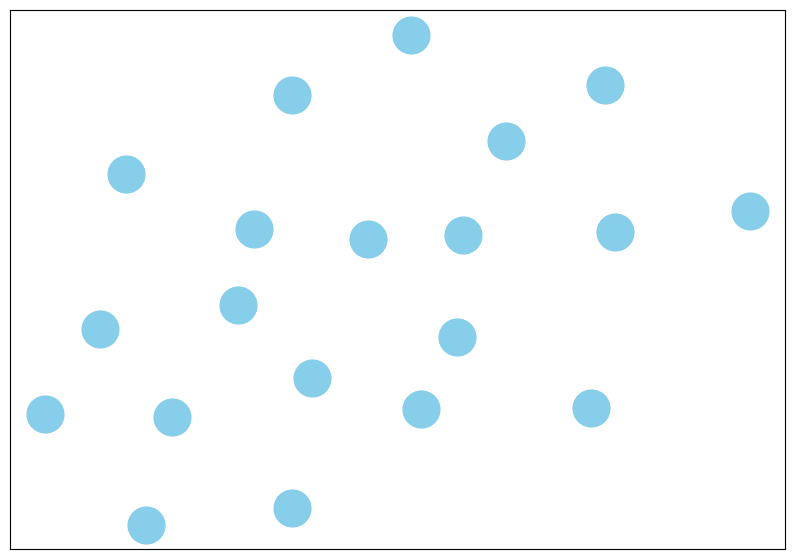

In [80]:
#visualize shortest path

path, cost = dijkstra(G, "A", "L")
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="skyblue",
    node_size=700
)



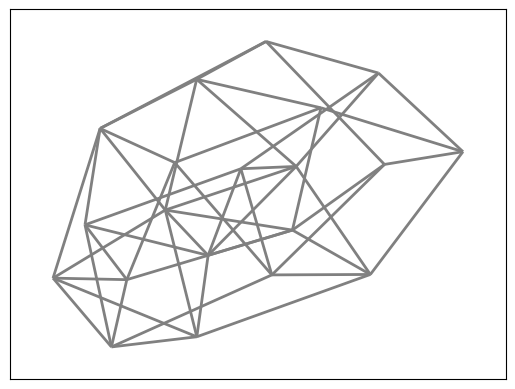

In [81]:
nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    width=2
)

{'A': Text(0.13556391713691196, 0.8038138241790274, 'A'),
 'B': Text(0.6292114964275426, 0.6413568222950067, 'B'),
 'C': Text(-0.1687229371949044, 0.6091594654344663, 'C'),
 'D': Text(-0.5925739179116356, 0.3565591532717297, 'D'),
 'E': Text(0.02518186229645011, 0.14911709007108115, 'E'),
 'F': Text(0.26795664570458533, 0.16120951525392305, 'F'),
 'G': Text(-0.30659238080169704, -0.06321452939368678, 'G'),
 'H': Text(-0.7992005741306722, -0.4133354215301637, 'H'),
 'I': Text(-0.6589520270777196, -0.13939934907819054, 'I'),
 'J': Text(-0.1185698872688772, -0.2963511972032075, 'J'),
 'K': Text(-0.16814731133962857, -0.71498746883522, 'K'),
 'L': Text(-0.5428844064296399, -0.7672166866845578, 'L'),
 'M': Text(-0.47537164019928374, -0.42126386189234716, 'M'),
 'N': Text(0.2514966691434904, -0.16621946195214302, 'N'),
 'O': Text(0.593574575034856, -0.39449034515464654, 'O'),
 'P': Text(0.16117852023542212, -0.3967541129279619, 'P'),
 'Q': Text(-0.26522569172096067, 0.18090479833362727, 'Q')

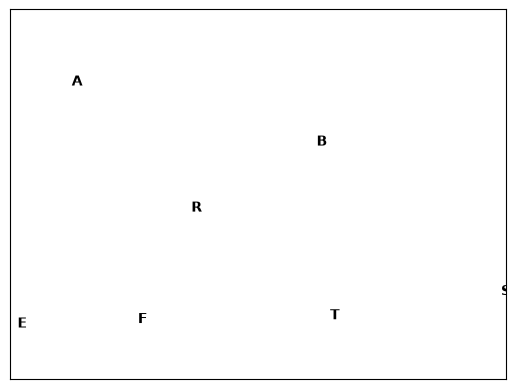

In [82]:
nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

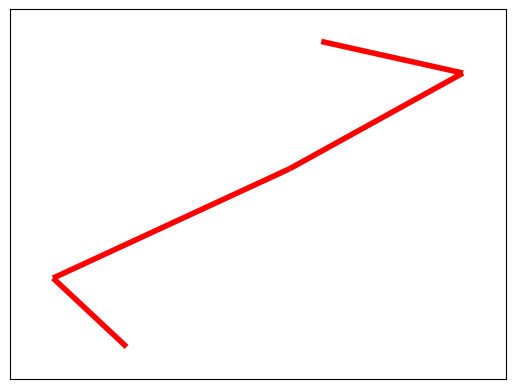

In [85]:
path_edges = list(zip(path[:-1], path[1:]))
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    edge_color="red",
    width=4
)

{('A', 'B'): Text(0.38238794820589106, 0.722585243785671, '5'),
 ('A', 'C'): Text(-0.016576168090812138, 0.7064887826672062, '3'),
 ('A', 'D'): Text(-0.22850408255796983, 0.5801870524970476, '4'),
 ('A', 'T'): Text(0.39551441374569374, 0.48762163771469186, '12'),
 ('B', 'E'): Text(0.3271965243980334, 0.3952368298988101, '6'),
 ('B', 'F'): Text(0.4485838943904896, 0.4012829339532546, '3'),
 ('B', 'S'): Text(0.814608050443739, 0.43917108029782365, '9'),
 ('C', 'D'): Text(-0.3806499801228461, 0.4828583840761083, '2'),
 ('C', 'G'): Text(-0.23765829941396516, 0.2729693447841788, '5'),
 ('C', 'R'): Text(0.10393766011441888, 0.5359290422997072, '7'),
 ('C', 'F'): Text(0.049611196745626585, 0.38519029386941034, '3'),
 ('D', 'G'): Text(-0.4495832988738797, 0.14667253140560638, '4'),
 ('D', 'H'): Text(-0.6958893037159901, -0.02839580113656226, '6'),
 ('D', 'Q'): Text(-0.42890207016711046, 0.26873319138505775, '6'),
 ('D', 'I'): Text(-0.6257622836639344, 0.10858504884572151, '5'),
 ('E', 'F'): Te

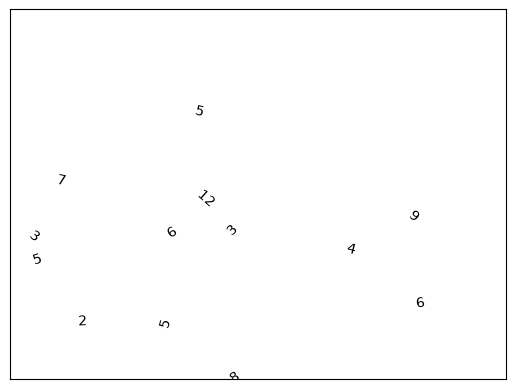

In [86]:
edge_labels = nx.get_edge_attributes(G, "distance")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

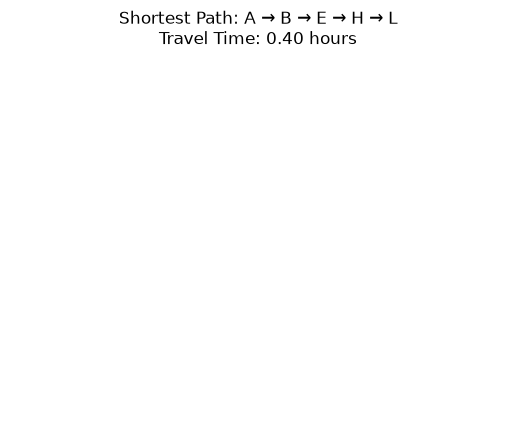

In [89]:
plt.title(
    f"Shortest Path: {' → '.join(path)}\nTravel Time: {cost:.2f} hours"
)
plt.axis("off")
plt.show()

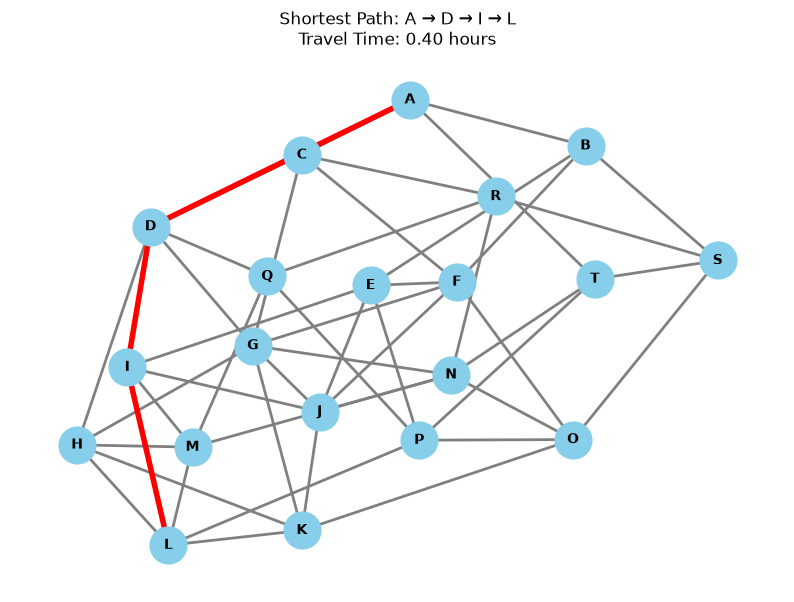

In [93]:
#VISUAL
#visualize shortest path

path, cost = dijkstra(G, "A", "L")
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(10, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="skyblue",
    node_size=700
)


nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    width=2
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold"
)

path_edges = list(zip(path[:-1], path[1:]))
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    edge_color="red",
    width=4
)

edge_labels = nx.get_edge_attributes(G, "distance")

'''nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)'''


plt.title(
    f"Shortest Path: {' → '.join(path)}\nTravel Time: {cost:.2f} hours"
)
plt.axis("off")
plt.show()

In [96]:
'''
replace this with
G = nx.from_pandas_edgelist(
    df_roads,
    source="source",
    target="destination",
    edge_attr=True
)
'''
def build_graph(time, weather):

    G = nx.from_pandas_edgelist(
        roads,
        source="source",
        target="destination",
        edge_attr=True
    )

    for u, v, data in G.edges(data=True):

        predicted_speed = predict_speed(
            distance=data["distance"],
            road_type=data["road_type"],
            time=time,
            weather=weather
        )

        data["travel_time"] = data["distance"] / predicted_speed

    return G

In [97]:
G = build_graph(
    time=8,
    weather="Rain"
)

path, cost = dijkstra(G, "A", "L")

print(path)
print(cost)

['A', 'D', 'I', 'L']
0.40178571428571425


In [98]:
G = build_graph(
    time=18,
    weather="Rain"
)

path, cost = dijkstra(G, "A", "L")

print(path)
print(cost)

['A', 'D', 'I', 'L']
0.40178571428571425


In [99]:
G = build_graph(
    time=14,
    weather="Sunny"
)

path, cost = dijkstra(G, "A", "L")

print(path)
print(cost)

['A', 'D', 'H', 'L']
0.27719290676101305


In [101]:
joblib.dump(model, "../models/decision_tree.pkl")
joblib.dump(list(x_train.columns), "../models/feature_columns.pkl")

['../models/feature_columns.pkl']